# Project 3: Equity Return Predictability

**Question:** Are post-2011 equity returns more predictable during economic downturns than during normal market conditions?
**Audience:** Pension fund managers and long-term institutional investors setting strategic asset allocation.

Runs from the files in `data/` only (see README for sources). Sections: 1 data and cleaning · 2 predictability table · 3 comparison with the slides · 4 DDM and buckets · 5 GARCH · 6 sensitivity · 7 downturns · 8 conclusion.

**Slide numbers** refer to the Ch. 8 deck as distributed, whose order differs from the assignment's: predictability table = deck slides 28, 32, 34 (assignment: 24–25); buckets = deck 37–39 (assignment: 26–28); GARCH = deck 41–43 (assignment: 31–33).

## 1. Data and cleaning

Everything is keyed by **calendar month** (CRSP dates are the last trading day, FRED dates the 1st). Each step is recorded in a cleaning log (req. 4), shown at the end of the section.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

DATA = Path("data")
cleaning_log = []

def log_step(dataset, step, affected, remaining, note=""):
    cleaning_log.append(dict(dataset=dataset, step=step, obs_affected=int(affected),
                             obs_remaining=int(remaining), note=note))

def month_ord(dates):
    # Calendar month as an integer (same numbering as pandas monthly Periods).
    return (dates.dt.year - 1970) * 12 + dates.dt.month - 1

def to_period(ords):
    return pd.PeriodIndex.from_ordinals(np.asarray(ords, dtype="int64"), freq="M")

### 1.1 Returns and dividend yield (CRSP index)
* Return: `vwretd`, value-weighted **including dividends** (req. 3); `ewretd` for sensitivity.
* Dividend yield: dividends backed out of the index, $D_t = (\text{vwretd}_t - \text{vwretx}_t)\,P_{t-1}$, summed over 12 months and divided by the price index $P_t$. Built from the index so it starts in **1926**, like the slides (req. 7).

In [2]:
crsp = pd.read_csv(DATA / "crsp_index.csv", parse_dates=["mthcaldt"])
crsp["month"] = crsp["mthcaldt"].dt.to_period("M")
dups = crsp["month"].duplicated().sum()
crsp = crsp.drop_duplicates("month", keep="last").set_index("month").sort_index()
log_step("CRSP index", "Duplicate months removed", dups, len(crsp))
log_step("CRSP index", "Months with a missing return",
         crsp[["vwretd", "vwretx", "ewretd", "ewretx"]].isna().any(axis=1).sum(), len(crsp))
log_step("CRSP index", "Gaps in the monthly calendar",
         len(pd.period_range(crsp.index.min(), crsp.index.max(), freq="M").difference(crsp.index)), len(crsp))
log_step("CRSP index", "Return incl. dividends < return excl. dividends (should be 0)",
         (crsp["vwretd"] < crsp["vwretx"] - 1e-9).sum(), len(crsp))

P = (1 + crsp["vwretx"]).cumprod()
D = (crsp["vwretd"] - crsp["vwretx"]) * P.shift(1).fillna(1.0)
crsp["div_yield"] = D.rolling(12).sum() / P
log_step("CRSP index", "Dividend yield undefined (first 11 months)", crsp["div_yield"].isna().sum(),
         crsp["div_yield"].notna().sum())

### 1.2 Earnings yield (Compustat earnings / CRSP market value)
$EY_t = \sum_i E_i / \sum_i ME_{i,t}$: latest available annual earnings (`ib`) over **current** month-end CRSP market value.
* Standard Compustat records only; duplicate firm-dates and repeated fiscal years (fiscal year-end changes) removed.
* No look-ahead: a report is used from **6 months** after fiscal year end (Fama–French convention), for at most 12 months.
* Firms matched through primary CCM links within their valid dates; share classes summed. No filter on *current* exchange (it would drop delisted firms: survivorship bias).
* A month is used only if **≥ 500 firms** report; earlier Compustat coverage is too thin to represent the market.

In [3]:
DS = "Earnings yield"
ca = pd.read_csv(DATA / "compustat_annual.csv", parse_dates=["datadate"], low_memory=False)
n = len(ca)
ca = ca[(ca["indfmt"] == "INDL") & (ca["datafmt"] == "STD") & (ca["consol"] == "C") & (ca["curcd"] == "USD")]
log_step(DS, "Compustat: non-standard records removed", n - len(ca), len(ca))
n = len(ca); ca = ca.sort_values(["gvkey", "datadate"]).drop_duplicates(["gvkey", "datadate"], keep="last")
log_step(DS, "Compustat: duplicate firm-dates removed", n - len(ca), len(ca))
n = len(ca); ca = ca.drop_duplicates(["gvkey", "fyear"], keep="last")
log_step(DS, "Compustat: repeated fiscal years removed (kept later report)", n - len(ca), len(ca))
n = len(ca); ca = ca.dropna(subset=["ib"]).reset_index(drop=True)
log_step(DS, "Compustat: missing earnings removed", n - len(ca), len(ca))

# Each report is active from 6 months after fiscal year end, for 12 months; the newest report wins.
ca["avail"] = month_ord(ca["datadate"]) + 6
acct = ca.loc[ca.index.repeat(12), ["gvkey", "datadate", "avail", "ib"]]
acct["month"] = acct["avail"].to_numpy() + np.tile(np.arange(12), len(ca))
n = len(acct); acct = acct.sort_values("datadate").drop_duplicates(["gvkey", "month"], keep="last")
log_step(DS, "Compustat: firm-months where a newer report replaces an older one", n - len(acct), len(acct))

stock = pd.read_csv(DATA / "crsp_stock_compact.csv", parse_dates=["MthCalDt"])
n = len(stock); stock = stock.drop_duplicates()
log_step(DS, "CRSP stocks: exact duplicate security-months removed", n - len(stock), len(stock))
n = len(stock); stock = stock[stock["MthCap"] > 0]
log_step(DS, "CRSP stocks: non-positive market value removed", n - len(stock), len(stock))
stock["month"] = month_ord(stock["MthCalDt"])

links = pd.read_csv(DATA / "ccm_links.csv")
n = len(links); links = links[links["LINKTYPE"].isin(["LC", "LU"]) & links["LINKPRIM"].isin(["P", "C"])].copy()
log_step(DS, "CCM: links that are not primary LC/LU removed", n - len(links), len(links))
links["start"] = month_ord(pd.to_datetime(links["LINKDT"]))
links["end"] = month_ord(pd.to_datetime(links["LINKENDDT"], errors="coerce")).fillna(10**6)   # "E" = still active
m = stock.merge(links[["gvkey", "LPERMNO", "start", "end", "LINKPRIM"]], left_on="PERMNO", right_on="LPERMNO")
m = m[(m["month"] >= m["start"]) & (m["month"] <= m["end"])]
n = len(m); m = m.sort_values("LINKPRIM", key=lambda s: s.map({"P": 0, "C": 1})).drop_duplicates(["PERMNO", "month"])
log_step(DS, "CRSP stocks: two valid links in a month (kept the primary one)", n - len(m), len(m))
log_step(DS, "CRSP stocks: no valid link to Compustat (not used)", len(stock) - len(m), len(m))

# Market value: CRSP $ thousands -> $ millions, summed over a firm's share classes.
cap = m.groupby(["gvkey", "month"], as_index=False)["MthCap"].sum()
matched = cap.merge(acct[["gvkey", "month", "ib"]], on=["gvkey", "month"])
agg = matched.groupby("month").agg(earn=("ib", "sum"), me=("MthCap", "sum"), n_firms=("gvkey", "size"))
agg.index = to_period(agg.index)
thin = agg["n_firms"] < 500
log_step(DS, "Months with fewer than 500 firms dropped", thin.sum(), (~thin).sum())
earnings_yield = (agg["earn"] / (agg["me"] / 1000))[~thin]
del stock, m, cap, matched

### 1.3 Macro, risk and return-based predictors
The 14 slide predictors. A value dated month $t$ must be known at the end of month $t$:
* **No lag** for market data: rates and spreads (`T10Y3M` daily → monthly mean, BAA − AAA, `TB3MS`), VIX and oil (last trading day).
* **1-month lag** for CPI, industrial production, unemployment (published the following month). GDP: each quarter used from 4 months after it starts (release ≈ end of following month).
* Inflation, IP, oil: 12-month log changes; GDP: 4-quarter log change. Series are put on a full monthly calendar first, so a missing month (Oct 2025 CPI) stays missing.
* Past 1-year return (months $t-11..t$); past-quarter volatility (std. of the 3 monthly returns $t-2..t$; a proxy, the slides likely use daily data).
* cay (Lettau–Ludvigson): each quarter used from the end of the next quarter, carried 2 months, not extended past 2019Q3.
* NBER `USREC` classifies downturns only (not a predictor), so it is not lagged.

In [4]:
DS = "FRED"

def load_fred(code):
    df = pd.read_csv(DATA / f"{code}.csv", parse_dates=["observation_date"])
    s = pd.to_numeric(df[code], errors="coerce")
    log_step(DS, f"{code}: missing values dropped", s.isna().sum(), s.notna().sum())
    return pd.Series(s.to_numpy(), index=df["observation_date"]).dropna()

def monthly(s, lag=0):
    # Key by calendar month on a complete monthly calendar (missing months stay missing).
    s = s.copy()
    s.index = s.index.to_period("M") + lag
    return s.reindex(pd.period_range(s.index.min(), s.index.max(), freq="M"))

raw = {c: load_fred(c) for c in ["T10Y3M", "TB3MS", "BAA", "AAA", "CPIAUCSL", "INDPRO", "UNRATE",
                                 "DCOILWTICO", "USREC", "GDPC1", "VIXCLS"]}
oil = monthly(raw["DCOILWTICO"].resample("ME").last())
log_step(DS, "DCOILWTICO: non-positive month-end price", (oil <= 0).sum(), oil.notna().sum(),
         "the -$37 price of 20 Apr 2020 is mid-month")

gdp = np.log(raw["GDPC1"]).diff(4).dropna()
gdp.index = gdp.index.to_period("M") + 4
gdp = gdp.reindex(pd.period_range(gdp.index.min(), gdp.index.max() + 2, freq="M")).ffill()

cay_raw = pd.read_csv(DATA / "cay_current.csv", parse_dates=["date"])
cay_col = [c for c in cay_raw.columns if c.lower().startswith("cay")][0]
cay = pd.Series(cay_raw[cay_col].to_numpy(), index=cay_raw["date"].dt.to_period("M") + 3)
log_step("cay", "Missing values / duplicate quarters", cay.isna().sum() + cay.index.duplicated().sum(), len(cay))
cay = cay.reindex(pd.period_range(cay.index.min(), cay.index.max() + 2, freq="M")).ffill(limit=2)

r = crsp["vwretd"]
preds = pd.DataFrame({
    "div_yield":        crsp["div_yield"],
    "earnings_yield":   earnings_yield,
    "vix":              monthly(raw["VIXCLS"].resample("ME").last()),
    "past_vol_quarter": r.rolling(3).std(),
    "cay":              cay,
    "term_spread":      monthly(raw["T10Y3M"].resample("ME").mean()) / 100,
    "credit_spread":    (monthly(raw["BAA"]) - monthly(raw["AAA"])) / 100,
    "unemployment":     monthly(raw["UNRATE"], lag=1) / 100,
    "gdp_growth":       gdp,
    "ip_growth":        np.log(monthly(raw["INDPRO"], lag=1)).diff(12),
    "past_1y_return":   np.expm1(np.log1p(r).rolling(12).sum()),
    "inflation":        np.log(monthly(raw["CPIAUCSL"], lag=1)).diff(12),
    "oil_change":       np.log(oil.where(oil > 0)).diff(12),
    "risk_free_rate":   monthly(raw["TB3MS"]) / 100,
})
predictors = list(preds.columns)

### 1.4 Outliers and winsorization
* **Not winsorized:** returns, valuation ratios, spreads, rates, VIX, unemployment, past returns/volatility, cay. Their extremes (1932, 2008, 2020) are real bad-times states, where the slides' risk-aversion argument says predictability should be strongest (deck slides 31 and 33, 'From the CML to the Equity Premium' and 'Why Should Business-Cycle Variables Predict Returns?'); deck slide 38 (assignment 27) stresses that the wide range of outcomes is real.
* **Winsorized at 1/99:** the growth rates (inflation, IP, GDP, oil), whose extremes are one-off shocks (post-war demobilisation, 2008 oil collapse, 2020 lockdown). Raw copies kept for sensitivity.

In [5]:
z = (preds - preds.mean()) / preds.std()
outliers = pd.DataFrame({
    "months beyond 4 sd": (z.abs() > 4).sum(),
    "examples": {c: ", ".join(str(m) for m in z.index[z[c].abs() > 4][:5]) for c in predictors},
})

for c in ["inflation", "ip_growth", "gdp_growth", "oil_change"]:
    s = preds[c]
    lo, hi = s.quantile([0.01, 0.99])
    log_step("Winsorization", f"{c} clipped to [{lo:.4f}, {hi:.4f}]", ((s < lo) | (s > hi)).sum(), s.notna().sum())
    preds[c + "_raw"] = s
    preds[c + "_w5"] = s.clip(*s.quantile([0.05, 0.95]))   # alternative cut-off (sensitivity)
    preds[c] = s.clip(lo, hi)
outliers

,months beyond 4 sd,examples
div_yield,3,"1932-04, 1932-05, 1932-06"
earnings_yield,0,
vix,3,"2008-10, 2008-11, 2020-03"
past_vol_quarter,10,"1931-10, 1931-11, 1932-07, 1932-08, 1932-09"
cay,0,
term_spread,0,
credit_spread,11,"1931-10, 1931-11, 1931-12, 1932-01, 1932-04"
unemployment,2,"2020-05, 2020-06"
gdp_growth,3,"2020-08, 2020-09, 2020-10"
ip_growth,2,"1933-08, 1946-03"


### 1.5 Monthly panel and future returns
Predictors are joined onto the CRSP calendar (Jan 1926 – Dec 2025); missing values are **not filled**, so each predictor uses its own sample.
Future return over months $t+1..t+h$, $h$ = 3, 12, 24, 60: $R_{t \to t+h} = \prod_{k=1}^{h}(1 + r_{t+k}) - 1$. **Excess returns** (main, as on the slides) subtract the compounded T-bill return, $r^f = (1+\text{TB3MS})^{1/12} - 1$, so they start in 1934. Nominal returns are kept for sensitivity.

In [6]:
outside = len(preds.index.difference(crsp.index))
panel = crsp[["vwretd", "ewretd"]].join(preds)
panel["usrec"] = monthly(raw["USREC"])
panel["downturn_nber"] = panel["usrec"] == 1
panel["post2011"] = panel.index >= pd.Period("2012-01", "M")
log_step("Alignment", "Predictor months outside Jan 1926 - Dec 2025 dropped", outside, len(panel))

HORIZONS = {"1Q": 3, "1Y": 12, "2Y": 24, "5Y": 60}

def future(monthly_ret, h):
    # Compounded return over months t+1 .. t+h.
    return np.expm1(np.log1p(monthly_ret).rolling(h).sum().shift(-h))

rf_month = (1 + panel["risk_free_rate"]) ** (1 / 12) - 1
for name, h in HORIZONS.items():
    rf_h = future(rf_month, h)
    for ret in ["vwretd", "ewretd"]:
        panel[f"fwd_{name}_{ret[:2]}_nominal"] = future(panel[ret], h)
        panel[f"fwd_{name}_{ret[:2]}"] = panel[f"fwd_{name}_{ret[:2]}_nominal"] - rf_h
    log_step("Future returns", f"{name}: no complete future excess return (last {h} months, pre-1934)",
             panel[f"fwd_{name}_vw"].isna().sum(), panel[f"fwd_{name}_vw"].notna().sum())

### 1.6 Cleaning log and coverage

In [7]:
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(cleaning_log)

,dataset,step,obs_affected,obs_remaining,note
0,CRSP index,Duplicate months removed,0,1200,
1,CRSP index,Months with a missing return,0,1200,
2,CRSP index,Gaps in the monthly calendar,0,1200,
3,CRSP index,Return incl. dividends < return excl. dividends (should be 0),0,1200,
4,CRSP index,Dividend yield undefined (first 11 months),11,1189,
5,Earnings yield,Compustat: non-standard records removed,0,527343,
6,Earnings yield,Compustat: duplicate firm-dates removed,0,527343,
7,Earnings yield,Compustat: repeated fiscal years removed (kept later report),11,527332,
8,Earnings yield,Compustat: missing earnings removed,84478,442854,
9,Earnings yield,Compustat: firm-months where a newer report replaces an older one,4011,5310237,


In [8]:
coverage = pd.DataFrame({c: {
    "start": panel[c].first_valid_index(), "end": panel[c].last_valid_index(),
    "months": panel[c].notna().sum(),
    "NBER months": (panel[c].notna() & panel["downturn_nber"]).sum(),
    "post-2011 NBER months": (panel[c].notna() & panel["downturn_nber"] & panel["post2011"]).sum(),
} for c in predictors}).T
coverage

,start,end,months,NBER months,post-2011 NBER months
div_yield,1926-12,2025-12,1189,200,2
earnings_yield,1960-06,2025-12,787,94,2
vix,1990-01,2025-12,432,36,2
past_vol_quarter,1926-03,2025-12,1198,201,2
cay,1952-06,2020-02,813,111,0
term_spread,1982-01,2025-12,528,47,2
credit_spread,1926-01,2025-12,1200,201,2
unemployment,1948-02,2025-12,934,124,2
gdp_growth,1948-05,2025-12,932,124,2
ip_growth,1926-01,2025-12,1200,201,2


## 2. Predictability table

For each predictor $x$ and horizon $h$ (3, 12, 24, 60 months): the **correlation** between $x_t$ and the future excess return $R^e_{t \to t+h}$, and the **t-statistic** of $b$ in the predictive regression $R^e_{t \to t+h} = a + b\,x_t + \varepsilon_{t+h}$ (in a one-variable regression, $b$ and the correlation have the same sign and significance).

**Overlapping observations (req. 5).** With monthly data, consecutive $h$-month returns share $h-1$ months, so the errors are autocorrelated and ordinary standard errors overstate the evidence (a 5-year regression on 600 months has only about 10 independent observations). The t-statistics use **Newey–West (HAC) standard errors with $h-1$ lags**, which allows for exactly that overlap. Sensitivity to this choice (more lags, non-overlapping observations) is in Section 5.

Each predictor uses all months where it and the future return exist. Two samples:
* **Through 2011**: future returns ending by Dec 2011, the end of the slides' sample.
* **Extended**: all data through Dec 2025 (req. 7).

In [9]:
import statsmodels.api as sm

LABELS = {
    "div_yield": "Dividend yield", "earnings_yield": "Earnings yield", "vix": "VIX",
    "past_vol_quarter": "Past volatility (last quarter)", "cay": "Consumption–wealth ratio",
    "term_spread": "Term spread (10y − 3m)", "credit_spread": "Credit spread (BAA − AAA)",
    "unemployment": "Unemployment rate", "gdp_growth": "GDP growth (past year)",
    "ip_growth": "Industrial production (past year)", "past_1y_return": "Past 1-year return",
    "inflation": "Inflation (past year)", "oil_change": "Oil price (past-year change)",
    "risk_free_rate": "Risk-free rate",
}

def predictive(df, x, h, ret="vw", lags=None):
    # Correlation and Newey-West t-stat of x_t with the future h-month return.
    y = f"fwd_{[k for k, v in HORIZONS.items() if v == h][0]}_{ret}"
    d = df[[x, y]].dropna()
    fit = sm.OLS(d[y], sm.add_constant(d[x])).fit(cov_type="HAC", cov_kwds={"maxlags": h - 1 if lags is None else lags})
    return {"corr": d[x].corr(d[y]), "t": fit.tvalues[x], "n": len(d),
            "start": d.index.min(), "end": d.index.max()}

def run_table(df, **kw):
    rows = [{"predictor": x, "horizon": name, **predictive(df, x, h, **kw)}
            for x in predictors for name, h in HORIZONS.items()]
    return pd.DataFrame(rows).set_index(["predictor", "horizon"])

def through_2011(df, h):
    # Keep origins whose future return ends by Dec 2011.
    return df[df.index <= pd.Period("2011-12", "M") - h]

extended = run_table(panel)
pre2012 = pd.concat([run_table(through_2011(panel, h)).xs(name, level="horizon", drop_level=False)
                     for name, h in HORIZONS.items()]).reindex(extended.index)

In [10]:
def slide_style(res, caption):
    # Slide format: "correlation (t-stat)", blue bold where |t| > 2.
    order = list(HORIZONS)
    cells = res.apply(lambda r: f"{r['corr']:.2f} ({r['t']:.2f})", axis=1).unstack("horizon")[order]
    sig = (res["t"].abs() > 2).unstack("horizon")[order]
    cells, sig = cells.reindex(predictors), sig.reindex(predictors)
    cells.index = [LABELS[p] for p in cells.index]
    sig.index = cells.index
    return (cells.style
            .apply(lambda col: np.where(sig[col.name], "color:#0070c0;font-weight:bold", ""), axis=0)
            .set_caption(caption))

slide_style(extended, "Extended sample (to Dec 2025): correlation with future excess return (Newey-West t-stat)")

horizon,1Q,1Y,2Y,5Y
Dividend yield,0.12 (2.46),0.25 (3.12),0.33 (3.21),0.47 (3.79)
Earnings yield,0.06 (1.10),0.10 (1.03),0.10 (0.96),0.12 (0.97)
VIX,0.14 (1.26),0.17 (1.58),0.13 (1.08),0.01 (0.04)
Past volatility (last quarter),0.12 (2.33),0.05 (1.05),0.04 (0.65),0.02 (0.23)
Consumption–wealth ratio,0.13 (2.61),0.21 (2.27),0.27 (2.08),0.26 (1.54)
Term spread (10y − 3m),-0.01 (-0.21),0.06 (0.57),0.19 (1.19),0.37 (2.62)
Credit spread (BAA − AAA),0.07 (1.19),0.15 (1.70),0.12 (1.03),0.09 (0.65)
Unemployment rate,0.14 (3.20),0.17 (2.16),0.08 (0.74),0.24 (1.53)
GDP growth (past year),-0.18 (-3.76),-0.19 (-2.41),-0.12 (-1.34),-0.17 (-1.50)
Industrial production (past year),-0.11 (-2.02),-0.14 (-1.52),-0.03 (-0.34),-0.05 (-0.50)


In [11]:
slide_style(pre2012, "Sample ending Dec 2011 (as on the slides)")

horizon,1Q,1Y,2Y,5Y
Dividend yield,0.15 (2.96),0.31 (3.57),0.41 (3.68),0.58 (4.58)
Earnings yield,0.08 (1.33),0.13 (1.14),0.15 (1.18),0.24 (1.57)
VIX,0.09 (0.70),0.13 (1.02),0.13 (0.73),-0.30 (-0.94)
Past volatility (last quarter),0.12 (2.00),0.03 (0.60),0.02 (0.25),-0.02 (-0.31)
Consumption–wealth ratio,0.15 (2.62),0.26 (2.60),0.38 (3.37),0.39 (2.85)
Term spread (10y − 3m),0.04 (0.53),0.20 (1.81),0.41 (2.59),0.40 (2.77)
Credit spread (BAA − AAA),0.07 (1.14),0.14 (1.48),0.10 (0.83),0.03 (0.23)
Unemployment rate,0.13 (2.53),0.17 (1.76),0.10 (0.78),0.20 (1.09)
GDP growth (past year),-0.15 (-2.84),-0.15 (-1.73),-0.09 (-1.01),-0.10 (-1.01)
Industrial production (past year),-0.10 (-1.71),-0.11 (-1.18),-0.01 (-0.11),0.00 (0.04)


In [12]:
# Sample used for each predictor (extended sample, 1-year horizon) and the number of
# non-overlapping observations behind the 5-year results.
samples = pd.DataFrame({
    "first month": extended.xs("1Y", level="horizon")["start"],
    "last month (1Y)": extended.xs("1Y", level="horizon")["end"],
    "N (1Y)": extended.xs("1Y", level="horizon")["n"],
    "N (5Y)": extended.xs("5Y", level="horizon")["n"],
    "independent 5Y windows": (extended.xs("5Y", level="horizon")["n"] / 60).round(1),
}).reindex(predictors)
samples.index = [LABELS[p] for p in samples.index]
samples

,first month,last month (1Y),N (1Y),N (5Y),independent 5Y windows
Dividend yield,1933-12,2024-12,1093,1045,17.4
Earnings yield,1960-06,2024-12,775,727,12.1
VIX,1990-01,2024-12,420,372,6.2
Past volatility (last quarter),1933-12,2024-12,1093,1045,17.4
Consumption–wealth ratio,1952-06,2020-02,813,813,13.6
Term spread (10y − 3m),1982-01,2024-12,516,468,7.8
Credit spread (BAA − AAA),1933-12,2024-12,1093,1045,17.4
Unemployment rate,1948-02,2024-12,923,875,14.6
GDP growth (past year),1948-05,2024-12,920,872,14.5
Industrial production (past year),1933-12,2024-12,1093,1045,17.4


## 3. Comparison with the slides (req. 8; deck slides 28, 32, 34 = assignment slides 24–25)

The slides' values (`lecture_benchmarks.csv`) next to ours, for the sample ending 2011 (closest to the slides) and the extended sample.

In [13]:
bm = pd.read_csv(DATA / "lecture_benchmarks.csv")
bm["predictor"] = bm["predictor"].map({
    "Dividend_yield": "div_yield", "Earnings_yield": "earnings_yield", "VIX": "vix",
    "Past_volatility": "past_vol_quarter", "Consumption_wealth_ratio": "cay",
    "Term_spread": "term_spread", "Credit_spread": "credit_spread", "Unemployment": "unemployment",
    "GDP_growth": "gdp_growth", "IP_growth": "ip_growth", "Past_1year_return": "past_1y_return",
    "Inflation": "inflation", "Oil_growth": "oil_change", "Risk_free_rate": "risk_free_rate"})
bm["horizon"] = bm["horizon_months"].map({v: k for k, v in HORIZONS.items()})
bm = bm.set_index(["predictor", "horizon"]).reindex(extended.index)

compare = pd.DataFrame({
    "slide corr": bm["slide_corr"], "slide t": bm["slide_t"],
    "to-2011 corr": pre2012["corr"], "to-2011 t": pre2012["t"],
    "extended corr": extended["corr"], "extended t": extended["t"],
})
compare["same sign (to 2011)"] = np.sign(compare["slide corr"]) == np.sign(compare["to-2011 corr"])
compare["same sign (extended)"] = np.sign(compare["slide corr"]) == np.sign(compare["extended corr"])
compare["|t|>2: slide / to-2011 / extended"] = [
    "/".join("yes" if abs(v) > 2 else "no" for v in (a, b, c))
    for a, b, c in zip(compare["slide t"], compare["to-2011 t"], compare["extended t"])]
compare.round(2)

slide corr  slide t  to-2011 corr  to-2011 t  \
predictor        horizon                                                 
div_yield        1Q             0.12     1.12          0.15       2.96   
                 1Y             0.23     1.25          0.31       3.57   
                 2Y             0.33     1.48          0.41       3.68   
                 5Y             0.49     1.95          0.58       4.58   
earnings_yield   1Q             0.18     2.23          0.08       1.33   
                 1Y             0.33     2.55          0.13       1.14   
                 2Y             0.41     2.79          0.15       1.18   
                 5Y             0.48     2.31          0.24       1.57   
vix              1Q             0.12     0.96          0.09       0.70   
                 1Y             0.10     0.63          0.13       1.02   
                 2Y             0.13     0.75          0.13       0.73   
                 5Y            -0.16    -0.47         -0.30      -0.94   
past_vol_quarter 1Q             0.05     0.55          0.12       2.00   
                 1Y             0.09     0.65          0.03       0.60   
                 2Y             0.13     0.78          0.02       0.25   
                 5Y             0.06     0.17         -0.02      -0.31   
cay              1Q             0.16     2.92          0.15       2.62   
                 1Y             0.30     2.62          0.26       2.60   
                 2Y             0.42     2.23          0.38       3.37   
                 5Y             0.53     1.34          0.39       2.85   
term_spread      1Q             0.11     1.60          0.04       0.53   
                 1Y             0.23     1.84          0.20       1.81   
                 2Y             0.27     1.66          0.41       2.59   
                 5Y             0.35     1.61          0.40       2.77   
credit_spread    1Q             0.02     0.15          0.07       1.14   
                 1Y             0.08     0.34          0.14       1.48   
                 2Y             0.12     0.44          0.10       0.83   
                 5Y             0.20     0.67          0.03       0.23   
unemployment     1Q             0.12     1.86          0.13       2.53   
                 1Y             0.22     1.85          0.17       1.76   
                 2Y             0.19     1.08          0.10       0.78   
                 5Y             0.22     0.75          0.20       1.09   
gdp_growth       1Q             0.01     0.17         -0.15      -2.84   
                 1Y            -0.13    -1.37         -0.15      -1.73   
                 2Y            -0.11    -1.25         -0.09      -1.01   
                 5Y            -0.08    -0.84         -0.10      -1.01   
ip_growth        1Q            -0.01    -0.06         -0.10      -1.71   
                 1Y            -0.04    -0.25         -0.11      -1.18   
                 2Y             0.02     0.08         -0.01      -0.11   
                 5Y            -0.04    -0.20          0.00       0.04   
past_1y_return   1Q            -0.01    -0.12         -0.03      -0.59   
                 1Y            -0.05    -0.26         -0.15      -1.85   
                 2Y            -0.13    -0.55         -0.21      -2.93   
                 5Y            -0.26    -1.39         -0.17      -2.06   
inflation        1Q            -0.07    -1.07         -0.12      -1.98   
                 1Y            -0.12    -0.94         -0.16      -1.64   
                 2Y            -0.10    -0.58         -0.16      -1.77   
                 5Y            -0.03    -0.09         -0.05      -0.52   
oil_change       1Q            -0.10    -1.20         -0.17      -1.86   
                 1Y            -0.18    -1.20         -0.27      -1.64   
                 2Y            -0.16    -1.08         -0.32      -2.17   
                 5Y            -0.11    -0.78         -0.20      -1.48   
risk_free_rate   1Q           

In [14]:
# Summary per predictor: sign agreement with the slides (out of 4 horizons) and average gap in correlation.
summary = pd.DataFrame({
    "same sign as slides, to 2011 (of 4)": compare["same sign (to 2011)"].groupby(level=0).sum(),
    "same sign as slides, extended (of 4)": compare["same sign (extended)"].groupby(level=0).sum(),
    "mean |corr gap|, to 2011": (compare["to-2011 corr"] - compare["slide corr"]).abs().groupby(level=0).mean(),
    "mean |corr gap|, extended": (compare["extended corr"] - compare["slide corr"]).abs().groupby(level=0).mean(),
    "significant horizons: slide": (compare["slide t"].abs() > 2).groupby(level=0).sum(),
    "significant horizons: extended": (compare["extended t"].abs() > 2).groupby(level=0).sum(),
}).reindex(predictors)
summary.index = [LABELS[p] for p in summary.index]
summary.round(2)

,"same sign as slides, to 2011 (of 4)","same sign as slides, extended (of 4)","mean |corr gap|, to 2011","mean |corr gap|, extended",significant horizons: slide,significant horizons: extended
Dividend yield,4,4,0.07,0.01,0,4
Earnings yield,4,4,0.20,0.25,4,0
VIX,4,3,0.05,0.07,0,0
Past volatility (last quarter),3,4,0.08,0.06,0,1
Consumption–wealth ratio,4,4,0.06,0.13,3,3
Term spread (10y − 3m),4,3,0.07,0.10,0,1
Credit spread (BAA − AAA),4,4,0.07,0.06,0,0
Unemployment rate,4,4,0.05,0.05,0,2
GDP growth (past year),3,3,0.06,0.09,0,2
Industrial production (past year),2,3,0.06,0.07,0,1


**Why are our t-statistics larger than the slides' for similar correlations?** Even at 1 quarter, where returns barely overlap, the slides' t-statistic is about a third of ours (dividend yield: 0.12 (1.12) on the slide). For a correlation of 0.12, $t = 1.12$ implies only about $(1.12/0.12)^2 \approx 90$–$300$ effective observations, which suggests the slides were estimated on **quarterly data over a shorter sample** (e.g. 1952–2011, 240 quarters), not ~900 overlapping months. The check below re-estimates at quarterly frequency over 1952–2011: correlations stay close to the slides and the t-statistics move toward theirs.

In [15]:
def quarterly(x, h, start="1952-01", end="2011-12"):
    # Quarter-end observations only; Newey-West lags = overlapping quarters.
    name = [k for k, v in HORIZONS.items() if v == h][0]
    d = panel.loc[pd.Period(start, "M"):pd.Period(end, "M") - h, [x, f"fwd_{name}_vw"]]
    d = d[d.index.month.isin([3, 6, 9, 12])].dropna()
    fit = sm.OLS(d.iloc[:, 1], sm.add_constant(d[x])).fit(cov_type="HAC", cov_kwds={"maxlags": max(h // 3 - 1, 1)})
    return d[x].corr(d.iloc[:, 1]), fit.tvalues[x]

q = pd.DataFrame([quarterly(x, h) for x in predictors for h in HORIZONS.values()],
                 index=extended.index, columns=["corr", "t"])
pd.DataFrame({
    "monthly, to 2011": (pre2012["t"] / bm["slide_t"]).median(),
    "quarterly, 1952-2011": (q["t"] / bm["slide_t"]).median(),
}, index=["median ratio: our t / slide t"]).round(2)

,"monthly, to 2011","quarterly, 1952-2011"
median ratio: our t / slide t,1.5,1.24


### Comparison with the slides

**Consistent:**
* **Signs agree** in 52 of 56 cells, both through 2011 and in the extended sample. In each of the four disagreements, one of the two correlations is within ±0.02 of zero, so the sign carries no information.
* **Size of the correlations is close** for most predictors (typical gap 0.04–0.10), and the main pattern of the slides holds: valuation ratios and cay rise with horizon; volatility (VIX, past volatility) and credit spread predict little.
* **Dividend yield** matches the slides almost exactly in the extended sample (0.12, 0.25, 0.33, 0.47 against 0.12, 0.23, 0.33, 0.49).

**Material differences and why:**
1. **t-statistics.** Ours are larger for similar correlations because we use ~900 overlapping monthly observations; the slides appear to use quarterly data over a shorter sample (see the check above). The **correlations are comparable, the t-statistics are not one-for-one**. Stricter corrections are tested in Section 5.
2. **Earnings yield** is much weaker in our data (0.06–0.24 against 0.18–0.48). Ours is the latest annual Compustat earnings over current market value, from 1960. The slides' version most likely uses S&P 500 earnings back to 1926 (their bucket charts use Shiller's 10-year-smoothed earnings). Annual earnings include one-off write-offs (2001–02, 2008–09) that make the ratio jump when nothing has changed in valuations; smoothing removes this noise.
3. **Different index and risk-free rate.** We use the CRSP value-weighted index (all US stocks) and a T-bill yield converted to a monthly return; the slides' bucket charts use the S&P 500.
4. **Data definitions and vintages.** FRED macro data and cay are today's revised series; past volatility uses 3 monthly returns (the slides probably use daily); VIX is the month-end value.

**Adding post-2011 data (extended vs. to 2011):**
* **Valuation predictability weakens but survives.** Dividend yield correlations fall (5-year: 0.58 → 0.47; 1-year: 0.31 → 0.25) but stay significant: yields were low after 2011 (≈ 1.3–2%) and returns were nonetheless high, against the model's prediction.
* **cay and the term spread weaken** (cay 5-year 0.39 → 0.26; term spread 1-year 0.20 → 0.06).
* **Several business-cycle variables become significant** at some horizons (inflation, GDP growth, unemployment, oil, past 1-year return), but their correlations change little (by 0.01–0.07); they cross $|t| = 2$ mainly because the extended sample adds observations. The COVID period is not the driver: excluding origins from mid-2019 to mid-2021 leaves the correlations almost unchanged, though a few borderline 1-year t-statistics fall back just under 2 (Section 5).

## 4. Dividend discount model and bucket analysis

### 4.1 Why valuation ratios should predict returns
The constant-growth dividend discount model, $P = D / (E(r) - g)$, rearranges to
$$\frac{D}{P} = E(r) - g .$$
A high dividend yield means either high expected returns or low expected dividend growth. If dividend growth is hard to predict, movements in $D/P$ (and $E/P$) must mostly reflect **expected returns**: when prices fall relative to dividends, future returns are higher. The test below checks that premise in our data: does the dividend yield predict future **dividend growth** (it should, with a negative sign, if prices move on growth news) or future **returns**?

In [16]:
# Dividend growth: 12-month dividends (from 1.1) grow over the next h months.
annual_div = D.rolling(12).sum()
for name, h in HORIZONS.items():
    if h >= 12:
        panel[f"divg_{name}"] = np.log(annual_div.shift(-h) / annual_div).reindex(panel.index)

def ols_corr_t(x, y, h):
    d = panel[[x, y]].dropna()
    fit = sm.OLS(d[y], sm.add_constant(d[x])).fit(cov_type="HAC", cov_kwds={"maxlags": h - 1})
    return f"{d[x].corr(d[y]):.2f} ({fit.tvalues[x]:.2f})"

pd.DataFrame({
    "future excess return": [ols_corr_t("div_yield", f"fwd_{n}_vw", h) for n, h in HORIZONS.items() if h >= 12],
    "future dividend growth": [ols_corr_t("div_yield", f"divg_{n}", h) for n, h in HORIZONS.items() if h >= 12],
}, index=[n for n, h in HORIZONS.items() if h >= 12]).rename_axis("dividend yield predicts...")

,future excess return,future dividend growth
dividend yield predicts...,,
1Y,0.25 (3.12),-0.38 (-2.63)
2Y,0.33 (3.21),-0.31 (-1.88)
5Y,0.47 (3.79),-0.16 (-1.53)


**Reading the test.** At 1 year, a high dividend yield predicts both higher returns and lower dividend growth, so part of short-run yield movements is news about dividends (e.g. the 1930s, when prices fell before dividends were cut). At longer horizons the balance shifts: return predictability rises (0.25 → 0.47) while dividend-growth predictability fades and is not significant at 5 years (−0.16, t = −1.53). Over long horizons, yield movements mostly reflect **expected returns**, as the model and deck slide 27 ('Building Block 1: The Dividend Discount Model') say.

**Why predictability is stronger at longer horizons.** The dividend yield is very persistent: it stays high or low for years. Each month adds a small predictable piece to expected returns, and these pieces accumulate over the horizon, while the unpredictable monthly shocks partly cancel out. The predictable share of the return therefore grows with the horizon, and correlations rise (dividend yield: 0.12 at 1 quarter to 0.47 at 5 years). Part of the rise is also mechanical, because overlapping long-horizon windows contain few independent observations (Section 2).

**The earnings yield** should work the same way ($E/P$ replaces $D/P$ when payout ratios are stable), but in our data it supports the prediction only weakly: correlations have the right sign but are small (0.06–0.12) and not significant (Section 2), and its buckets are nearly flat (4.2). Two reasons: annual earnings include one-off write-offs that move the ratio without any change in valuations, and our earnings yield moves with interest rates (Section 6), so it partly measures the level of rates rather than expected excess returns. The slides' version, likely based on smoothed S&P 500 earnings, avoids the first problem.

**Does the post-2011 data support the prediction?** For the dividend yield, yes, with less strength: adding 2012–2025 lowers the dividend-yield correlations (5-year: 0.58 → 0.47) but they keep the predicted sign and remain significant. The bucket analysis below shows where the post-2011 data departs from the model.

### 4.2 Buckets (deck slides 37–39 = assignment slides 26–28)
Months are sorted into five equal-sized buckets by the valuation ratio. For each bucket: the average future 1-year excess return and the average future 5-year excess return **per year**, with ±2 standard-deviation bands (roughly the range of 95% of outcomes). Dividend yield as on deck slide 39 (from 1934, the start of excess returns); earnings yield as a second valuation ratio (from 1960). The slides' P/E10 sort needs Shiller's smoothed earnings, which are not in our data.

In [17]:
import matplotlib.pyplot as plt

# 5-year excess return per year: annualize the stock and T-bill returns separately.
rf5 = panel["fwd_5Y_vw_nominal"] - panel["fwd_5Y_vw"]
panel["fwd_5Y_vw_ann"] = (1 + panel["fwd_5Y_vw_nominal"]) ** (1 / 5) - (1 + rf5) ** (1 / 5)

def bucket_table(x):
    d = panel[[x, "fwd_1Y_vw", "fwd_5Y_vw_ann", "post2011"]].dropna(subset=[x, "fwd_1Y_vw"]).copy()
    d["bucket"] = pd.qcut(d[x], 5, labels=[1, 2, 3, 4, 5])
    g = d.groupby("bucket", observed=True)
    t = pd.DataFrame({
        "avg ratio": g[x].mean(), "months": g.size(),
        "1Y mean": g["fwd_1Y_vw"].mean(), "1Y sd": g["fwd_1Y_vw"].std(),
        "5Y/yr mean": g["fwd_5Y_vw_ann"].mean(), "5Y/yr sd": g["fwd_5Y_vw_ann"].std(),
        "1Y share < 0": g["fwd_1Y_vw"].apply(lambda s: (s < 0).mean()),
        "post-2011 months": g["post2011"].sum(),
    })
    t["1Y low (−2sd)"] = t["1Y mean"] - 2 * t["1Y sd"]
    t["1Y high (+2sd)"] = t["1Y mean"] + 2 * t["1Y sd"]
    return t, d

bucket_dy, d_dy = bucket_table("div_yield")
bucket_ey, d_ey = bucket_table("earnings_yield")
bucket_dy.round(3)

,avg ratio,months,1Y mean,1Y sd,5Y/yr mean,5Y/yr sd,1Y share < 0,post-2011 months,1Y low (−2sd),1Y high (+2sd)
bucket,,,,,,,,,,
1,0.016,219,0.057,0.166,0.025,0.056,0.301,71,-0.275,0.389
2,0.024,218,0.072,0.173,0.093,0.072,0.289,85,-0.275,0.419
3,0.032,219,0.047,0.162,0.040,0.056,0.352,0,-0.276,0.371
4,0.040,218,0.098,0.198,0.072,0.046,0.321,0,-0.297,0.494
5,0.056,219,0.175,0.176,0.134,0.055,0.146,0,-0.177,0.527


In [18]:
bucket_ey.round(3)

,avg ratio,months,1Y mean,1Y sd,5Y/yr mean,5Y/yr sd,1Y share < 0,post-2011 months,1Y low (−2sd),1Y high (+2sd)
bucket,,,,,,,,,,
1,0.027,155,0.049,0.162,0.052,0.078,0.329,50,-0.275,0.373
2,0.042,155,0.116,0.133,0.075,0.066,0.187,54,-0.150,0.383
3,0.050,155,0.020,0.161,0.043,0.067,0.394,37,-0.302,0.341
4,0.061,155,0.072,0.179,0.052,0.064,0.239,15,-0.286,0.431
5,0.099,155,0.103,0.186,0.071,0.048,0.271,0,-0.269,0.475


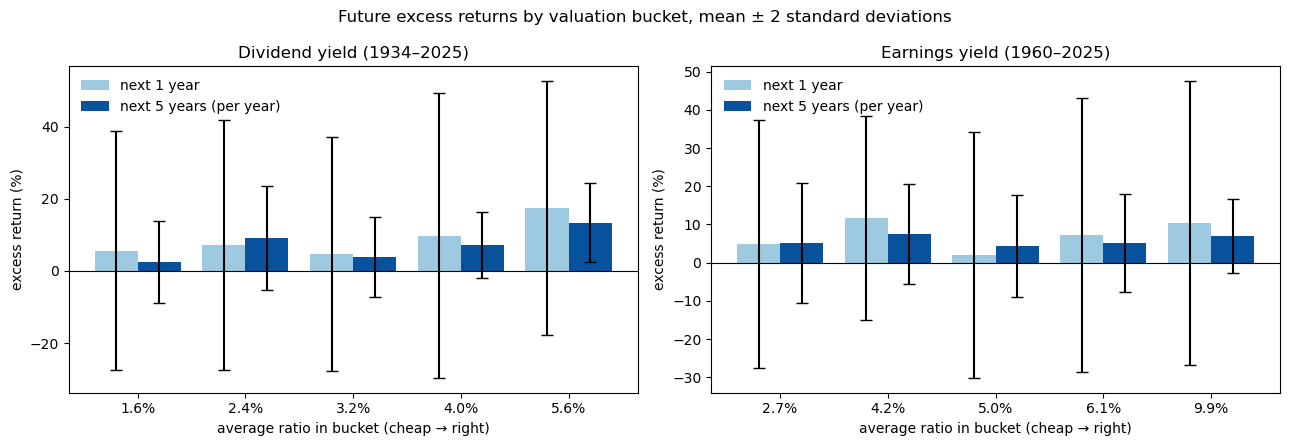

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (t, title) in zip(axes, [(bucket_dy, "Dividend yield (1934–2025)"), (bucket_ey, "Earnings yield (1960–2025)")]):
    pos = np.arange(5)
    ax.bar(pos - 0.2, 100 * t["1Y mean"], 0.4, yerr=200 * t["1Y sd"], capsize=4, label="next 1 year", color="#9ecae1")
    ax.bar(pos + 0.2, 100 * t["5Y/yr mean"], 0.4, yerr=200 * t["5Y/yr sd"], capsize=4, label="next 5 years (per year)", color="#08519c")
    ax.set_xticks(pos, [f"{100 * v:.1f}%" for v in t["avg ratio"]])
    ax.axhline(0, color="black", lw=0.8)
    ax.set(title=title, xlabel="average ratio in bucket (cheap → right)", ylabel="excess return (%)")
    ax.legend(frameon=False)
fig.suptitle("Future excess returns by valuation bucket, mean ± 2 standard deviations")
fig.tight_layout()
plt.show()

In [20]:
# Post-2011: where did those months sit, and how did they do against the full-sample bucket average?
post = d_dy[d_dy["post2011"]]
pd.DataFrame({
    "post-2011 months": post.groupby("bucket", observed=True).size(),
    "post-2011 1Y mean": post.groupby("bucket", observed=True)["fwd_1Y_vw"].mean(),
    "all-years 1Y mean": bucket_dy["1Y mean"],
}).round(3).rename_axis("dividend-yield bucket")

,post-2011 months,post-2011 1Y mean,all-years 1Y mean
dividend-yield bucket,,,
1,71.0,0.085,0.057
2,85.0,0.149,0.072
3,NaN,NaN,0.047
4,NaN,NaN,0.098
5,NaN,NaN,0.175


**Predictable, but weakly (deck slides 37–39).**
* **Average returns rise with cheapness.** The cheapest dividend-yield bucket earned 17.5% over the next year and 13.4% a year over five years, against 5.7% and 2.5% for the most expensive, close to deck slide 39 (16.7% / 14.7% against 3.7% / 2.3%). The middle buckets are not in order, so the pattern is driven mainly by the extremes.
* **The noise is huge.** The ±2 standard-deviation bands overlap across all buckets: even in the most expensive bucket, one-year returns range from about −28% to +39%. 15% of one-year returns from the cheapest bucket were still negative. The dividend yield explains only $0.25^2 \approx 6\%$ of the variation in one-year returns.
* **The earnings yield sort is much flatter** (5-year: 5.2% a year in the most expensive bucket, 7.1% in the cheapest), matching its weak correlations in Section 2.

**Post-2011.** Every post-2011 month sits in the two most expensive dividend-yield buckets, yet those months earned *more* than those buckets' historical averages (8.5% vs 5.7%; 14.9% vs 7.2% over the next year). Expensive markets kept rising, the risk deck slide 38 warns about. Part of the explanation is structural: firms increasingly pay out through buybacks rather than dividends, which lowers the dividend yield without lowering expected returns. With about 13 non-overlapping years after 2011, this is one episode, not proof that predictability has disappeared.

**Conclusion (req. 10).** Consistent with the slides: returns are predictable on average, but the predictable part is small relative to the noise. Valuation ratios are useful for setting long-run return expectations, not for timing the market year to year.

## 5. Returns vs. volatility: GARCH(1,1) (deck slides 41–43 = assignment slides 31–33)

Monthly CRSP value-weighted returns, 1926–2025, with a constant mean and
$\sigma^2_{t+1} = \omega + \alpha\,\varepsilon_t^2 + \beta\,\sigma^2_t$, estimated by maximum likelihood (normal errors). As on the slides, the model is estimated on the full sample.

**Realized volatility.** The slides compare against volatility realized during each period, computed from daily returns. We only have monthly returns, so realized volatility is the standard deviation of the 12 monthly returns over the **next 12 months** (annualized), compared with the GARCH forecast of average volatility over those same 12 months. A naive forecast (volatility over the *past* 12 months) is the benchmark.

In [21]:
from scipy.optimize import minimize

y = 100 * crsp["vwretd"]                        # percent, for numerical stability
mu = y.mean()
e = (y - mu).to_numpy()

def garch_var(params):
    w, a, b = params
    s2 = np.empty_like(e)
    s2[0] = e.var()
    for t in range(1, len(e)):
        s2[t] = w + a * e[t - 1] ** 2 + b * s2[t - 1]
    return s2

def neg_loglik(params):
    w, a, b = params
    if w <= 0 or a < 0 or b < 0 or a + b >= 1:
        return 1e10
    s2 = garch_var(params)
    return 0.5 * np.sum(np.log(2 * np.pi * s2) + e ** 2 / s2)

fit = minimize(neg_loglik, [0.1 * e.var(), 0.1, 0.85], method="Nelder-Mead",
               options={"maxiter": 10000, "xatol": 1e-8, "fatol": 1e-8})
assert fit.success, fit.message
w, a, b = fit.x
long_run = w / (1 - a - b)
pd.Series({"omega": w, "alpha (news)": a, "beta (memory)": b, "alpha + beta": a + b,
           "half-life of a shock (months)": np.log(0.5) / np.log(a + b),
           "long-run vol (annual, %)": np.sqrt(12 * long_run)}).round(4)

omega                             0.7432
alpha (news)                      0.1403
beta (memory)                     0.8369
alpha + beta                      0.9773
half-life of a shock (months)    30.1443
long-run vol (annual, %)         19.8072
dtype: float64

In [22]:
s2 = garch_var(fit.x)
s2_next = w + a * e ** 2 + b * s2              # forecast made at end of month t for month t+1

# GARCH forecast of average variance over months t+1..t+12, annualized volatility.
k = np.arange(12)
avg12 = long_run + (s2_next - long_run) * ((a + b) ** k).mean()
vol = pd.DataFrame(index=crsp.index)
vol["garch_12m"] = np.sqrt(12 * avg12) / 100
vol["garch_1m"] = np.sqrt(12 * s2_next) / 100
dev2 = pd.Series(e ** 2, index=crsp.index)
vol["realized_next_12m"] = np.sqrt(12 * dev2.rolling(12).mean().shift(-12)) / 100
vol["realized_past_12m"] = np.sqrt(12 * dev2.rolling(12).mean()) / 100
vol["abs_next_1m"] = np.sqrt(12) * np.abs(pd.Series(e, index=crsp.index).shift(-1)) / 100

v = vol.dropna()
best_return_corr = extended.xs("1Y", level="horizon")["corr"].abs()
pd.Series({
    "GARCH 12m forecast vs realized next 12m": v["garch_12m"].corr(v["realized_next_12m"]),
    "naive past-12m vol vs realized next 12m": v["realized_past_12m"].corr(v["realized_next_12m"]),
    "GARCH 1m forecast vs |next-month return|": v["garch_1m"].corr(v["abs_next_1m"]),
    "1-year return predictors: median |corr|": best_return_corr.median(),
    "1-year return predictors: largest |corr|": best_return_corr.max(),
    "average GARCH volatility (annual)": vol["garch_1m"].mean(),
}).round(3)

GARCH 12m forecast vs realized next 12m     0.635
naive past-12m vol vs realized next 12m     0.616
GARCH 1m forecast vs |next-month return|    0.408
1-year return predictors: median |corr|     0.167
1-year return predictors: largest |corr|    0.328
average GARCH volatility (annual)           0.169
dtype: float64

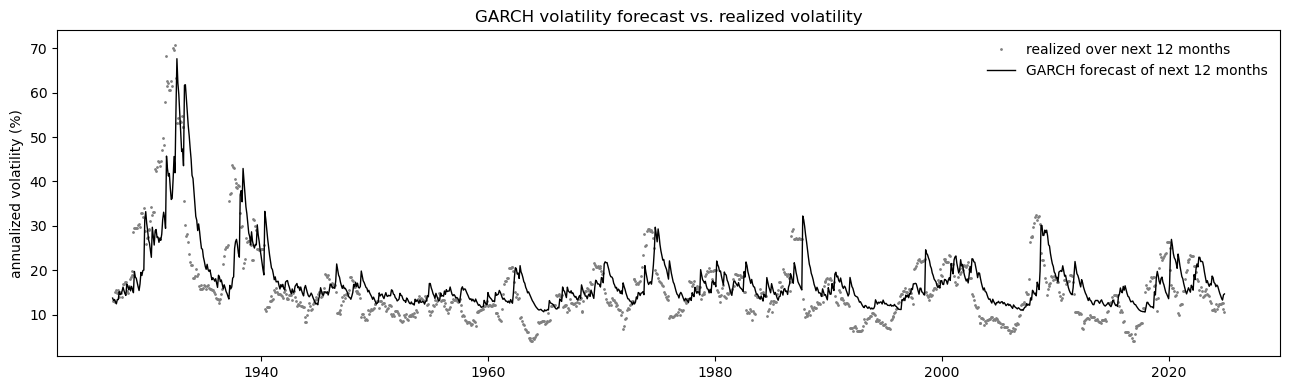

In [23]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(v.index.to_timestamp(), 100 * v["realized_next_12m"], ".", ms=2, color="grey", label="realized over next 12 months")
ax.plot(v.index.to_timestamp(), 100 * v["garch_12m"], color="black", lw=1, label="GARCH forecast of next 12 months")
ax.set(ylabel="annualized volatility (%)", title="GARCH volatility forecast vs. realized volatility")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

**Volatility is far more predictable than returns (deck slide 43).**
* **Estimates.** $\alpha \approx 0.14$ (news: a large shock raises next month's volatility) and $\beta \approx 0.84$ (memory). $\alpha + \beta \approx 0.98$, close to 1 as on deck slide 42: a volatility shock takes about 30 months to halve. Average GARCH volatility is about 17% a year (slides: 15.3%).
* **Forecast vs. realized.** The GARCH forecast of volatility over the next 12 months has a correlation of **0.64** with the volatility actually realized, almost exactly the slides' 0.63. The best one-year *return* predictor reaches 0.33 and the median 0.17.
* **Persistence does most of the work.** Simply using the past 12 months' volatility gives 0.62, nearly as good as GARCH: volatility is predictable because it is persistent. GARCH adds a forward-looking adjustment (shocks fade toward the long-run level), which helps most right after a spike.
* **One month ahead** the forecast still correlates 0.41 with the size of next month's return, which is noisy for a single month.
* Caveats: the model is estimated on the full sample (as on the slides, so this is in-sample), and realized volatility comes from 12 monthly returns rather than daily data.

**Conclusion (req. 11).** As concluded in class: volatility changes over time and is much more predictable than expected returns.

## 6. Sensitivity analysis (req. 12)

The Section 2 table re-run under alternative assumptions. For each predictor: the number of horizons (out of 4) with $|t| > 2$.
* **Overlap correction:** Newey–West with twice as many lags, $2(h-1)$; and **non-overlapping** observations (one every $h$ months, ordinary t-statistic; the median over the $h$ possible starting months).
* **Index and returns:** equal-weighted instead of value-weighted; nominal instead of excess returns.
* **Winsorization:** growth predictors without winsorizing, and with a 5/95 cut-off instead of 1/99.
* **Sub-periods:** forecast origins before 1990 / from 1990; excluding the COVID period (origins mid-2019 to mid-2021).

In [24]:
def nonoverlap(df, x, h, ret="vw"):
    y = f"fwd_{[k for k, v in HORIZONS.items() if v == h][0]}_{ret}"
    d = df[[x, y]].dropna()
    cs, ts = [], []
    for start in range(h):
        s = d.iloc[start::h]
        if len(s) >= 10:
            cs.append(s[x].corr(s[y]))
            ts.append(sm.OLS(s[y], sm.add_constant(s[x])).fit().tvalues[x])
    if not cs:                           # too few non-overlapping observations
        return {"corr": np.nan, "t": np.nan}
    return {"corr": np.median(cs), "t": np.median(ts)}

raw_name = lambda x: x + "_raw" if x + "_raw" in panel else x
w5_name = lambda x: x + "_w5" if x + "_w5" in panel else x
covid = (panel.index >= pd.Period("2019-07", "M")) & (panel.index <= pd.Period("2021-06", "M"))
SCENARIOS = {
    "Baseline": lambda x, h: predictive(panel, x, h),
    "NW 2(h-1) lags": lambda x, h: predictive(panel, x, h, lags=2 * (h - 1)),
    "Non-overlapping": lambda x, h: nonoverlap(panel, x, h),
    "Equal-weighted": lambda x, h: predictive(panel, x, h, ret="ew"),
    "Nominal returns": lambda x, h: predictive(panel, x, h, ret="vw_nominal"),
    "No winsorizing": lambda x, h: predictive(panel, raw_name(x), h),
    "Winsorize 5/95": lambda x, h: predictive(panel, w5_name(x), h),
    "Origins before 1990": lambda x, h: predictive(panel[panel.index < pd.Period("1990-01", "M")], x, h),
    "Origins 1990+": lambda x, h: predictive(panel[panel.index >= pd.Period("1990-01", "M")], x, h),
    "Excluding COVID": lambda x, h: predictive(panel[~covid], x, h),
}

def safe(f, x, h):
    try:
        return f(x, h)
    except (ValueError, KeyError):       # predictor has no data in that sub-period
        return {"corr": np.nan, "t": np.nan}

sens = pd.DataFrame([{"predictor": x, "horizon": n, "scenario": s, **safe(f, x, h)}
                     for s, f in SCENARIOS.items() for x in predictors for n, h in HORIZONS.items()])
sig_count = (sens.assign(sig=sens["t"].abs() > 2)
             .pivot_table(index="predictor", columns="scenario", values="sig", aggfunc="sum")
             .reindex(index=predictors, columns=list(SCENARIOS)))
sig_count.index = [LABELS[p] for p in sig_count.index]
sig_count.style.background_gradient(cmap="Blues", vmin=0, vmax=4).format("{:.0f}", na_rep="–") \
    .set_caption("Number of horizons (of 4) with |t| > 2")

scenario,Baseline,NW 2(h-1) lags,Non-overlapping,Equal-weighted,Nominal returns,No winsorizing,Winsorize 5/95,Origins before 1990,Origins 1990+,Excluding COVID
Dividend yield,4,4,4,4,3,4,4,4,3,4
Earnings yield,0,0,0,1,4,0,0,3,0,0
VIX,0,0,0,4,0,0,0,0,0,0
Past volatility (last quarter),1,1,1,2,0,1,1,1,0,0
Consumption–wealth ratio,3,3,1,0,3,3,3,4,0,3
Term spread (10y − 3m),1,1,0,2,1,1,1,1,1,1
Credit spread (BAA − AAA),0,0,0,3,0,0,0,0,2,0
Unemployment rate,2,2,1,2,3,2,2,0,3,1
GDP growth (past year),2,2,1,2,2,2,2,1,3,2
Industrial production (past year),1,0,1,0,0,1,1,0,0,0


In [25]:
# One-year correlations under each assumption (does the size of the effect move, not just its significance?).
corr_1y = sens[sens["horizon"] == "1Y"].pivot(index="predictor", columns="scenario", values="corr") \
    .reindex(index=predictors, columns=list(SCENARIOS))
corr_1y.index = [LABELS[p] for p in corr_1y.index]
corr_1y.round(2)

scenario,Baseline,NW 2(h-1) lags,Non-overlapping,Equal-weighted,Nominal returns,No winsorizing,Winsorize 5/95,Origins before 1990,Origins 1990+,Excluding COVID
Dividend yield,0.25,0.25,0.24,0.30,0.23,0.25,0.25,0.41,0.35,0.27
Earnings yield,0.10,0.10,0.10,0.21,0.23,0.10,0.10,0.31,0.17,0.12
VIX,0.17,0.17,0.17,0.36,0.15,0.17,0.17,NaN,0.17,0.09
Past volatility (last quarter),0.05,0.05,0.03,0.07,-0.00,0.05,0.05,0.03,0.08,0.02
Consumption–wealth ratio,0.21,0.21,0.22,0.12,0.22,0.21,0.21,0.30,0.05,0.23
Term spread (10y − 3m),0.06,0.06,0.06,0.19,0.02,0.06,0.06,0.22,0.02,0.10
Credit spread (BAA − AAA),0.15,0.15,0.15,0.24,0.15,0.15,0.15,0.13,0.21,0.14
Unemployment rate,0.17,0.17,0.16,0.23,0.20,0.17,0.17,0.09,0.28,0.16
GDP growth (past year),-0.19,-0.19,-0.18,-0.24,-0.18,-0.20,-0.19,-0.19,-0.20,-0.18
Industrial production (past year),-0.14,-0.14,-0.14,-0.11,-0.10,-0.13,-0.17,-0.14,-0.17,-0.11


**Which predictors survive?**
* **Dividend yield is the one robust predictor**: significant at 3–4 horizons under every assumption, including non-overlapping observations, with a 1-year correlation of 0.23–0.41.
* **Oil price change and GDP growth** stay significant at one horizon or more in every scenario (oil only from 1987). **Unemployment** does too, except before 1990.
* **Non-overlapping observations are the strictest test** and remove most other results (past 1-year return 3 → 0 horizons, inflation 3 → 1, cay 3 → 1, oil 4 → 1). This confirms that t-statistics from overlapping monthly data overstate the evidence, as the comparison with the slides suggested.
* **Earnings yield** is significant only with nominal returns (4 horizons), before 1990 (3) or equal-weighted (1). It moves with interest rates (correlation 0.69 with the T-bill rate), so it predicts the T-bill part of nominal returns rather than the equity premium.
* **cay** works before 1990 (4 horizons) but not after (0). **VIX and credit spread** matter only for equal-weighted returns, i.e. for smaller stocks.
* **Doubling the Newey–West lags or changing the winsorization (none, or 5/95 instead of 1/99) barely changes anything.**

**Effect on the economic question:** the robust finding is long-horizon predictability from the dividend yield; most macro and risk predictors depend on the sample, the index or the overlap correction.

## 7. Research question: is predictability stronger in downturns, and after 2011?

A month is classified by the state of the economy or market **at the forecast origin**. Three definitions:
* **NBER recession** (`USREC`): the standard definition of an economic downturn. Only 2 months after 2011 (the 2020 recession), so it is used for the historical comparison only.
* **Market drawdown ≥ 10%**: the value-weighted total-return index at least 10% below its previous peak. Available for the whole sample; after 2011 it covers 21 months in 5 episodes (2016, 2018, 2020, 2022, 2023).
* **High VIX**: month-end VIX above the 75th percentile of all *earlier* months (from 1995, once five years of history exist), so the classification uses only information available at the time. After 2011: 24 months in 9 episodes (2015, 2018, 2020–21, 2022, 2025). A financial-stress measure, not an economic one.

For each predictor and horizon, the predictive regression is extended with the state $S_t$ (1 in a downturn):
$$R^e_{t \to t+h} = a + b\,x_t + c\,S_t + d\,x_t S_t + \varepsilon,$$
so $d$ measures how much the predictive slope changes in downturns (Newey–West t-statistic, $h-1$ lags). We also report the correlation separately in downturn and normal months. A test is run only if both states have at least 12 observations.

In [26]:
tr = (1 + panel["vwretd"]).cumprod()
panel["downturn_drawdown"] = (tr / tr.cummax() - 1) <= -0.10
# High VIX: above the 75th percentile of all *earlier* months (needs 5 years of history), so no hindsight.
vix_cut = panel["vix"].expanding(min_periods=60).quantile(0.75).shift(1)
panel["downturn_vix"] = (panel["vix"] > vix_cut).astype(float).where(vix_cut.notna() & panel["vix"].notna())

def state_test(df, x, h, state):
    y = f"fwd_{[k for k, v in HORIZONS.items() if v == h][0]}_vw"
    d = df[[x, y, state]].dropna()
    s = d[state].astype(float)
    out = {"downturn obs": int(s.sum()), "normal obs": int((1 - s).sum())}
    if s.sum() < 12 or (1 - s).sum() < 12:
        return {**out, "corr normal": np.nan, "corr downturn": np.nan, "interaction t": np.nan}
    X = pd.DataFrame({"const": 1.0, "x": d[x], "s": s, "xs": d[x] * s})
    fit = sm.OLS(d[y], X).fit(cov_type="HAC", cov_kwds={"maxlags": h - 1})
    return {**out, "corr normal": d.loc[s == 0, x].corr(d.loc[s == 0, y]),
            "corr downturn": d.loc[s == 1, x].corr(d.loc[s == 1, y]), "interaction t": fit.tvalues["xs"]}

post2011 = panel[panel["post2011"]]
TESTS = {
    "Full sample, NBER recession": (panel, "downturn_nber"),
    "Full sample, drawdown ≥ 10%": (panel, "downturn_drawdown"),
    "Post-2011, drawdown ≥ 10%": (post2011, "downturn_drawdown"),
    "Post-2011, high VIX": (post2011, "downturn_vix"),
}
states = pd.DataFrame([{"test": name, "predictor": x, "horizon": n, **state_test(df, x, h, s)}
                       for name, (df, s) in TESTS.items() for x in predictors for n, h in HORIZONS.items()])

def summarize(g):
    ok = g.dropna(subset=["interaction t"])
    return pd.Series({
        "predictors tested": len(ok),
        "median downturn obs": ok["downturn obs"].median(),
        "avg |corr| normal": ok["corr normal"].abs().mean(),
        "avg |corr| downturn": ok["corr downturn"].abs().mean(),
        "stronger in downturn": (ok["corr downturn"].abs() > ok["corr normal"].abs()).sum(),
        "significant change (|t|>2)": (ok["interaction t"].abs() > 2).sum(),
    })

state_summary = states.groupby(["test", "horizon"], sort=False)[states.columns.drop(["test", "horizon"])].apply(summarize)
state_summary.round(2)

predictors tested  median downturn obs  \
test                        horizon                                           
Full sample, NBER recession 1Q                    14.0                124.0   
                            1Y                    14.0                124.0   
                            2Y                    14.0                124.0   
                            5Y                    14.0                124.0   
Full sample, drawdown ≥ 10% 1Q                    14.0                229.0   
                            1Y                    14.0                229.0   
                            2Y                    14.0                229.0   
                            5Y                    14.0                213.0   
Post-2011, drawdown ≥ 10%   1Q                    13.0                 21.0   
                            1Y                    13.0                 21.0   
                            2Y                    13.0                 21.0   
                            5Y                     0.0                  NaN   
Post-2011, high VIX         1Q                    13.0                 24.0   
                            1Y                    13.0                 23.0   
                            2Y                    13.0                 23.0   
                            5Y                    13.0                 12.0   

                                     avg |corr| normal  avg |corr| downturn  \
test                        horizon                                           
Full sample, NBER recession 1Q                    0.09                 0.21   
                            1Y                    0.14                 0.24   
                            2Y                    0.14                 0.24   
                            5Y                    0.18                 0.28   
Full sample, drawdown ≥ 10% 1Q                    0.10                 0.12   
                            1Y                    0.14                 0.18   
                            2Y                    0.17                 0.16   
                            5Y                    0.20                 0.26   
Post-2011, drawdown ≥ 10%   1Q                    0.16                 0.39   
                            1Y                    0.36                 0.41   
                            2Y                    0.35                 0.33   
                            5Y                     NaN                  NaN   
Post-2011, high VIX         1Q                    0.09                 0.43   
                            1Y                    0.29                 0.52   
                            2Y                    0.36                 0.45   
                            5Y                    0.26                 0.31   

                                     stronger in downturn  \
test                        horizon                         
Full sample, NBER recession 1Q                       12.0   
                            1Y                        9.0   
                            2Y                        8.0   
                            5Y                       10.0   
Full sample, drawdown ≥ 10% 1Q                        8.0   
                            1Y                        8.0   
                            2Y                        6.0   
                            5Y                        9.0   
Post-2011, drawdown ≥ 10%   1Q                       11.0   
                            1Y                        7.0   
                            2Y                        7.0   
                            5Y                        0.0   
Post-2011, high VIX         1Q                       11.0   
                            1Y                       11.0   
                            2Y                        9.0   
                            5Y                        7.0   

                                     significant change (|t|>2)  
test                      

In [27]:
# Detail at the 1-year horizon: correlation in normal / downturn months and the interaction t-stat.
detail = states[states["horizon"] == "1Y"].copy()
detail["cell"] = detail.apply(lambda r: "–" if pd.isna(r["interaction t"]) else
                              f"{r['corr normal']:.2f} / {r['corr downturn']:.2f} ({r['interaction t']:.1f})", axis=1)
detail = detail.pivot(index="predictor", columns="test", values="cell").reindex(index=predictors, columns=list(TESTS))
detail.index = [LABELS[p] for p in detail.index]
detail.style.set_caption("1-year horizon: corr normal / corr downturn (interaction t)")

test,"Full sample, NBER recession","Full sample, drawdown ≥ 10%","Post-2011, drawdown ≥ 10%","Post-2011, high VIX"
Dividend yield,0.15 / 0.50 (2.3),0.23 / 0.24 (0.0),0.44 / 0.72 (1.4),0.45 / 0.71 (2.1)
Earnings yield,-0.06 / 0.45 (3.2),0.02 / 0.24 (1.4),0.50 / 0.35 (0.1),0.54 / 0.58 (1.2)
VIX,0.11 / 0.60 (3.1),0.00 / 0.34 (1.8),0.24 / 0.44 (0.6),0.08 / 0.52 (2.1)
Past volatility (last quarter),-0.00 / 0.05 (0.6),-0.00 / 0.03 (0.3),0.17 / 0.03 (-0.6),0.06 / 0.27 (1.3)
Consumption–wealth ratio,0.26 / 0.06 (-0.5),0.28 / 0.08 (-0.7),–,–
Term spread (10y − 3m),0.07 / -0.05 (-0.5),0.08 / -0.06 (-0.9),-0.15 / -0.15 (-0.1),-0.17 / -0.59 (-2.3)
Credit spread (BAA − AAA),0.09 / 0.14 (0.2),-0.04 / 0.24 (1.8),0.41 / 0.57 (2.0),0.37 / 0.69 (4.5)
Unemployment rate,0.15 / 0.22 (0.8),0.11 / 0.30 (1.6),0.48 / 0.26 (1.2),0.20 / 0.49 (1.0)
GDP growth (past year),-0.13 / -0.22 (-0.9),-0.15 / -0.23 (-0.8),-0.57 / -0.15 (0.5),-0.49 / -0.47 (0.1)
Industrial production (past year),-0.05 / -0.25 (-1.6),-0.09 / -0.20 (-0.5),-0.60 / -0.65 (-1.7),-0.46 / -0.68 (-1.1)


**Placebo test.** The downturn groups are small (after 2011: about 15–25 months from a few episodes), and correlations estimated on small samples are large in absolute value by chance alone. Comparing average |correlation| between a small group and a large one is therefore biased toward "stronger in downturns". The fair benchmark: shift the downturn labels in time (circularly, so the fake downturns keep the same number and clustering of months) and recompute. The p-value is the share of shifted, fake downturns whose gap (average |corr| in downturn minus in normal months) is at least as large as the real one. Also run with 2020 excluded, to check the post-2011 result is not just COVID.

In [28]:
def corr_gap(df, state_values, h, ret="vw", col=lambda x: x):
    # Average |corr| in downturn months minus in normal months, across predictors.
    y = df[f"fwd_{[k for k, v in HORIZONS.items() if v == h][0]}_{ret}"].to_numpy()
    gaps_down, gaps_norm = [], []
    for x in predictors:
        xv = df[col(x)].to_numpy()
        ok = ~np.isnan(xv) & ~np.isnan(y) & ~np.isnan(state_values)
        down, norm = ok & (state_values == 1), ok & (state_values == 0)
        if down.sum() >= 12 and norm.sum() >= 12:
            gaps_down.append(abs(np.corrcoef(xv[down], y[down])[0, 1]))
            gaps_norm.append(abs(np.corrcoef(xv[norm], y[norm])[0, 1]))
    return np.mean(gaps_down) - np.mean(gaps_norm) if gaps_down else np.nan

def placebo(df, state, h, **kw):
    s = df[state].to_numpy(dtype=float)
    actual = corr_gap(df, s, h, **kw)
    fake = np.array([corr_gap(df, np.roll(s, k), h, **kw) for k in range(1, len(s))])
    fake = fake[~np.isnan(fake)]
    return {"gap (down − normal)": actual, "placebo median gap": np.median(fake),
            "p-value": (fake >= actual).mean(), "placebos": len(fake)}

excl_2020 = post2011[post2011.index.year != 2020]
PLACEBO_TESTS = {**TESTS,
                 "Post-2011, drawdown ≥ 10%, excl. 2020": (excl_2020, "downturn_drawdown"),
                 "Post-2011, high VIX, excl. 2020": (excl_2020, "downturn_vix")}
placebo_table = pd.DataFrame([{"test": name, "horizon": n, **placebo(df, s, h)}
                              for name, (df, s) in PLACEBO_TESTS.items() for n, h in HORIZONS.items() if h <= 12])
placebo_table.set_index(["test", "horizon"]).round(3)

gap (down − normal)  \
test                                  horizon                        
Full sample, NBER recession           1Q                     0.119   
                                      1Y                     0.108   
Full sample, drawdown ≥ 10%           1Q                     0.017   
                                      1Y                     0.032   
Post-2011, drawdown ≥ 10%             1Q                     0.224   
                                      1Y                     0.050   
Post-2011, high VIX                   1Q                     0.335   
                                      1Y                     0.232   
Post-2011, drawdown ≥ 10%, excl. 2020 1Q                     0.327   
                                      1Y                     0.187   
Post-2011, high VIX, excl. 2020       1Q                     0.306   
                                      1Y                     0.155   

                                               placebo median gap  p-value  \
test                                  horizon                                
Full sample, NBER recession           1Q                    0.038    0.062   
                                      1Y                    0.053    0.190   
Full sample, drawdown ≥ 10%           1Q                    0.012    0.460   
                                      1Y                    0.016    0.359   
Post-2011, drawdown ≥ 10%             1Q                    0.090    0.132   
                                      1Y                   -0.002    0.406   
Post-2011, high VIX                   1Q                    0.059    0.012   
                                      1Y                    0.047    0.114   
Post-2011, drawdown ≥ 10%, excl. 2020 1Q                    0.116    0.065   
                                      1Y                    0.058    0.282   
Post-2011, high VIX, excl. 2020       1Q                    0.126    0.052   
                                      1Y                    0.066    0.333   

                                               placebos  
test                                  horizon            
Full sample, NBER recession           1Q           1199  
                                      1Y           1199  
Full sample, drawdown ≥ 10%           1Q           1199  
                                      1Y           1199  
Post-2011, drawdown ≥ 10%             1Q            167  
                                      1Y            160  
Post-2011, high VIX                   1Q            167  
                                      1Y            167  
Post-2011, drawdown ≥ 10%, excl. 2020 1Q            155  
                                      1Y            142  
Post-2011, high VIX, excl. 2020       1Q            155  
                                      1Y            141

**Does the answer change under other assumptions? (req. 12)** The two main downturn tests re-run with the alternatives from Section 6 that apply here. The test is based on correlations, so the Newey–West lag choice does not affect it, and the downturn samples are too small for non-overlapping observations.

In [29]:
ALTERNATIVES = {
    "Baseline": {},
    "Equal-weighted": {"ret": "ew"},
    "Nominal returns": {"ret": "vw_nominal"},
    "No winsorizing": {"col": raw_name},
    "Winsorize 5/95": {"col": w5_name},
}
answer_rows = []
for test in ["Full sample, NBER recession", "Post-2011, high VIX"]:
    df, state = TESTS[test]
    variants = {**{k: (df, v) for k, v in ALTERNATIVES.items()},
                "Excluding 2020": (df[df.index.year != 2020], {})}
    for alt, (d_alt, kw) in variants.items():
        for n, h in [("1Q", 3), ("1Y", 12)]:
            r = placebo(d_alt, state, h, **kw)
            answer_rows.append({"test": test, "assumption": alt, "horizon": n,
                                "gap": r["gap (down − normal)"], "p-value": r["p-value"]})
answer = pd.DataFrame(answer_rows).pivot_table(index=["test", "assumption"], columns="horizon",
                                                values=["gap", "p-value"], sort=False)
answer.round(3)

gap        p-value       
horizon                                         1Q     1Y      1Q     1Y
test                        assumption                                  
Full sample, NBER recession Baseline         0.119  0.108   0.062  0.190
                            Equal-weighted   0.135  0.119   0.035  0.128
                            Nominal returns  0.080  0.106   0.294  0.336
                            No winsorizing   0.119  0.108   0.063  0.188
                            Winsorize 5/95   0.117  0.111   0.056  0.171
                            Excluding 2020   0.131  0.123   0.046  0.152
Post-2011, high VIX         Baseline         0.335  0.232   0.012  0.114
                            Equal-weighted   0.225  0.197   0.054  0.138
                            Nominal returns  0.331  0.238   0.018  0.114
                            No winsorizing   0.334  0.229   0.018  0.114
                            Winsorize 5/95   0.333  0.234   0.012  0.108
                            Excluding 2020   0.306  0.155   0.052  0.333

**Results.**
* **History (1934–2025).** In NBER recessions most predictors correlate more strongly with future returns (average |corr| 0.21 against 0.09 at one quarter; stronger for 12 of 14 predictors), for example the dividend yield 0.15 → 0.50 at one year. Against the placebo the difference is only marginal at one quarter (p = 0.06) and not significant at one year (p = 0.19). Market drawdowns show no difference (p ≥ 0.36).
* **After 2011, financial stress (high VIX).** Predictability is stronger at one quarter: average |corr| 0.43 against 0.09, p = 0.01 against the placebo. Without 2020 the p-value rises to 0.05, so the COVID episode contributes but does not create the result on its own. At one year the gap is not significant (p = 0.11; 0.33 without 2020).
* **After 2011, market drawdowns.** Not significant (p = 0.13 at one quarter, 0.41 at one year).
* **Caveats.** The post-2011 stress sample is 24 months from 9 episodes. Four post-2011 placebo tests were run (2 definitions × 2 horizons), so a single p ≈ 0.01 is borderline once multiple testing is allowed for. VIX is both the state variable and one of the predictors. NBER recessions after 2011 (2 months) are too few to test.

**Does the answer change? (req. 12)** The post-2011 one-quarter result has p ≈ 0.01–0.02 with nominal returns and either winsorization alternative, but rises to about 0.05 with equal-weighted returns or without 2020; the one-year result is never significant (p ≥ 0.11). The historical recession result stays marginal at one quarter (p = 0.035–0.06) under the alternatives, except with nominal returns (0.29), and is never significant at one year. The answer therefore does not change direction, but its strength depends on the assumptions: the evidence is suggestive, not robust.

## 8. Conclusion

**Are post-2011 equity returns more predictable during downturns than during normal conditions?** *Partly, and only weakly.* After 2011, returns over the following quarter were more predictable during periods of financial stress (high VIX): p = 0.01 in the baseline, but about 0.05 without 2020 or with equal-weighted returns, and the result rests on 9 stress episodes. There is no reliable evidence at one year or longer, and none when downturns are defined by market drawdowns. Over the full history, recessions show the same direction, but the difference is statistically marginal. Official recessions after 2011 are too few to test directly.

**For pension fund managers and long-term investors:**
* The robust signal is the **dividend yield over long horizons**: cheap markets have been followed by higher returns. It is useful for setting long-run return expectations, but it is noisy (Section 4) and has been weaker since 2011, when low yields were followed by high returns, partly because of the shift from dividends to buybacks.
* The stronger predictability in stress periods is **short-lived and rests on few episodes**. It does not justify changing strategic allocation. At most it supports rebalancing discipline in stressed markets (not selling equities after a sharp fall), since expected returns tend to be higher then.
* **Volatility is far more predictable than returns** (Section 5): risk budgets and exposure can reasonably respond to forecast volatility, while return-timing should not.